# Orsia versus SASKTRAN2: five-band comparison

Compare top-of-atmosphere radiance, spectral residuals and calculation times in UV, VNIR, SWIR, MWIR and LWIR using the same atmospheric optical properties. The figures and summary quantify agreement between the two solvers for this scene.

UV/VNIR/SWIR model reflected sunlight; MWIR/LWIR model nighttime absorption-only LTE emission. Both use scalar plane-parallel transport and a Lambertian surface. Radiance and absolute residuals are in W m⁻² sr⁻¹ (cm⁻¹)⁻¹; wavelength is the plotting coordinate. Relative residuals use SASKTRAN2 as the denominator at nonzero samples.


In [1]:
from pathlib import Path
from datetime import datetime
import runpy, sys
import numpy as np
# Embed figures during kernel execution; standalone helpers keep their backend.
if 'get_ipython' in globals(): get_ipython().run_line_magic('matplotlib', 'inline')
from scipy.constants import atomic_mass
from orsia_data import read_netcdf_profiles, read_hitran_lines, read_partition_table, read_solar_spectrum_csv
from orsia_radiative import (pressure_level_layer_means, gas_columns_from_fraction, hydrostatic_atmosphere, wavenumber_grid, line_set, line_absorption, compose_absorption_on_grid, atmospheric_optics, solar_irradiance, solar_source, RayleighComponent, SurfaceState, ObservationGeometry, RadiativeScene)
from orsia_radiative.transfer import solar, thermal
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'notebooks/support/notebook_sasktran2_layers.py').is_file(), 'Start in orsia/ or orsia/notebooks/'
sys.path.insert(0, str(ROOT))
from notebooks.support.notebook_five_band_support import (
    verify_inputs, time_orsia as measure_orsia, show_atmosphere,
    show_comparison, show_agreement, show_timing,
)
cached_reference = runpy.run_path(str(ROOT / 'notebooks/support/notebook_sasktran2_cache.py'))['reference']
gas_helpers = runpy.run_path(str(ROOT / 'notebooks/support/five_band_gases.py'))


## Inputs and settings

The local enriched manifest supplies ERA5 temperature/humidity, HITRAN lines, MIPAS trace-gas profiles, measured UV cross sections and HSRS solar irradiance. Input checksums are verified on every run. The [input and enrichment guide](../docs/five-band-enrichment.md) describes species, profile conversion and laboratory temperature support; UV temperatures use the nearest supported endpoint when required.

Each window uses 201 equally spaced wavenumber samples. Solar surface albedo is 0.20; thermal emissivity is 0.97 at 300 K. Solar zenith and viewing zenith angles are 30° and 10°. The prescribed atmosphere spans 1000–1 hPa; surface properties and background abundances define an illustrative scene. The shared Rayleigh law is an approximate dry-air sensitivity model. Atmospheric completeness, polarization, continuum, line mixing, instrument response and retrieval performance have separate validation scopes.

| Band | Wavelength [nm] | Orsia order / angular order / subdivisions |
| --- | --- | --- |
| UV | 320–325 | 16 / 4 / 2 |
| VNIR | 758–765 | 2 / 2 / 1 |
| SWIR | 1645–1655 | 1 / 2 / 1 |
| MWIR | 4250–4300 | Absorption-only Schwarzschild, exponential integrals |
| LWIR | 9950–10050 | Absorption-only Schwarzschild, exponential integrals |

Delta-M is off. SASKTRAN2 uses 32 interior altitude nodes per physical layer and 32 streams. Its thermal boundary adapter adds reflected downward atmospheric LTE emission with 128-point hemispheric quadrature. Run the notebook with `devbox run -- just execute-five-band` from the repository root after preparing local inputs as described in `notebooks/README.md`.


In [2]:
MANIFEST = ROOT / 'outputs/five-band-enriched-inputs/manifest.json'
REFERENCE_PYTHON = ROOT / 'outputs/sasktran2-env/bin/python'
assert MANIFEST.is_file(), f'Provide local ERA5/HITRAN inputs: {MANIFEST}'
assert REFERENCE_PYTHON.is_file(), 'Provision the isolated reference environment first'
manifest, base, input_paths, provenance = verify_inputs(MANIFEST)
def local(name): return (base / name).resolve()
# Narrow representative windows, increasing cm-1 support. Edit explicitly.
CASES = {'UV': (320, 325, False), 'VNIR': (758, 765, False), 'SWIR': (1645, 1655, False), 'MWIR': (4250, 4300, True), 'LWIR': (9950, 10050, True)}
POINTS = 201
ALBEDO = 0.2
EMISSIVITY = 0.97
SURFACE_TEMPERATURE_K = 300.0
MU0, MUV = np.cos(np.deg2rad([30.0, 10.0]))
# Historical shared controls retained for existing standalone benchmark helpers.
ORSIA_CONTROLS = dict(max_order=4, angular_order=8, layer_subdivisions=1)
UV_CONTROLS = dict(max_order=16, angular_order=4, layer_subdivisions=2)
SOLAR_CONTROLS = {'UV': UV_CONTROLS, 'VNIR': dict(max_order=2, angular_order=2, layer_subdivisions=1), 'SWIR': dict(max_order=1, angular_order=2, layer_subdivisions=1)}

TIMING_RUNS = 3
REFERENCE_CACHE = ROOT / 'outputs/sasktran2-reference-cache'
REFERENCE_CACHE_MODE = 'reuse'  # reuse: read/write; refresh: recompute/write; off: bypass


Local inputs verified; 26 checksums matched.


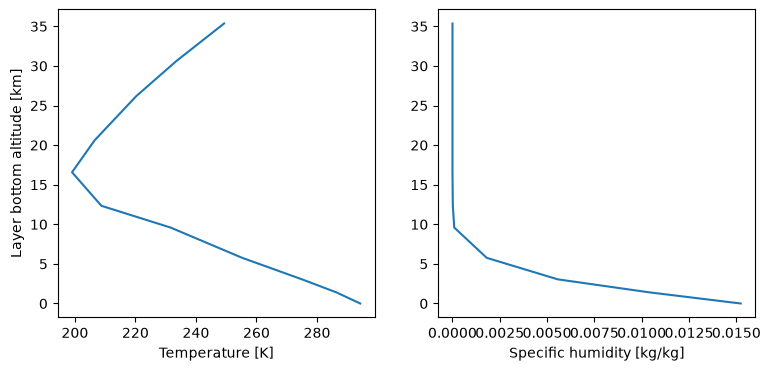

In [3]:
p, profiles = read_netcdf_profiles(local(manifest['era5']), variables={'t':'K','q':'kg kg-1'}, coordinates=tuple(manifest['coordinates']), vertical_units='Pa', valid_time=datetime.fromisoformat(manifest['valid_time']), latitude_deg=manifest['latitude_deg'], longitude_deg=manifest['longitude_deg'], backend=manifest['backend'])
interfaces = np.asarray(manifest['pressure_interfaces_pa'], dtype=float)
temperature = pressure_level_layer_means(p, profiles['t'], interfaces)
humidity = pressure_level_layer_means(p, profiles['q'], interfaces)
columns = {s['species']: gas_columns_from_fraction(interfaces, humidity, np.asarray(s['dry_air_mole_fraction'], dtype=float), convention='dry_air_mole', gravity_m_s2=9.80665) for s in manifest['spectroscopy'] if s['species'] != 'H2O' and 'dry_air_mole_fraction' in s}
profile_diagnostics = {}
if 'mipas' in manifest:
    trace_columns, profile_diagnostics = gas_helpers['project_trace_gases'](local(manifest['mipas']['file']), interfaces, humidity, manifest['mipas']['species'])
    columns.update(trace_columns)
atmosphere = hydrostatic_atmosphere(interfaces, temperature, humidity, target_pressure_boundaries_pa=interfaces, gravity_m_s2=9.80665, bottom_height_m=0.0, gas_columns_molecules_m2=columns, air_broadener='dry_air')
native_solar = read_solar_spectrum_csv(local(manifest['solar_csv']))
show_atmosphere(temperature, humidity, atmosphere)


In [4]:
absorption_components = {}
temperature_diagnostics = {}

def prepare_case(name, points=None):
    points = POINTS if points is None else points
    low_nm, high_nm, is_thermal = CASES[name]
    grid = wavenumber_grid(np.linspace(1e7 / high_nm, 1e7 / low_nm, points))
    components = []
    for s in manifest['spectroscopy']:
        if name not in s.get('included_cases', CASES): continue
        database = read_hitran_lines(local(s['lines']), molecule_id=s['molecule_id'], isotopologue_id=s['isotopologue_id'], interval_cm1=(grid.points[0]-26, grid.points[-1]+26))
        partition = read_partition_table(local(s['partition']), molecule_id=s['molecule_id'], isotopologue_id=s['isotopologue_id'])
        lines = line_set(database, partition, atmosphere, grid, species=s['species'], molecular_mass_kg=s['mass_u']*atomic_mass, pressure_range_pa=tuple(s['pressure_range_pa']), wing_cutoff_cm1=25.0)
        components.append(line_absorption(atmosphere, grid, lines))
    if name == 'UV' and 'cross_sections' in manifest:
        measured, report = gas_helpers['uv_components'](base, manifest['cross_sections'], atmosphere, grid)
        components.extend(measured)
        temperature_diagnostics[name] = report
    absorption_components[(name, points)] = tuple(components)
    absorption = compose_absorption_on_grid(atmosphere, grid, tuple(components), reference_atmospheres=tuple(atmosphere for _ in components))
    # Explicit scalar Rayleigh sensitivity law; approximate dry-air cross section.
    # Both solvers receive this same approximate dry-air model.
    wavelength_um = 1e4 / grid.points
    sigma_m2 = 5.1e-31 * (0.55 / wavelength_um)**4
    rayleigh_depth = np.zeros_like(absorption.optical_depth) if is_thermal else atmosphere.dry_air_columns_molecules_m2[:, None] * sigma_m2[None, :]
    rayleigh = RayleighComponent(grid, rayleigh_depth)
    optics = atmospheric_optics(atmosphere, grid, absorption=absorption, rayleigh=rayleigh)
    surface = SurfaceState(grid, emissivity=np.full(points, EMISSIVITY), temperature_k=SURFACE_TEMPERATURE_K) if is_thermal else SurfaceState(grid, reflectance=np.full(points, ALBEDO))
    scene = RadiativeScene(atmosphere, surface, ObservationGeometry(10.0))
    irradiance = None if is_thermal else solar_irradiance(native_solar, grid)
    source = None if is_thermal else solar_source(irradiance, direction=(30.0, 0.0))
    shared = dict(height_m=atmosphere.height_boundaries_m, temperature_k=temperature, wavenumbers_cm1=grid.points, absorption_depth=absorption.optical_depth, rayleigh_depth=rayleigh_depth, thermal=is_thermal, mu0=MU0, muv=MUV, irradiance=np.zeros(points) if is_thermal else irradiance.values, albedo=np.full(points, 1-EMISSIVITY if is_thermal else ALBEDO), emissivity=np.full(points, EMISSIVITY), surface_temperature_k=SURFACE_TEMPERATURE_K)
    return grid, scene, optics, source, shared

def reference(shared, cells, streams):
    return cached_reference(shared, cells, streams, runs=TIMING_RUNS, interpreter=REFERENCE_PYTHON, worker=ROOT/'notebooks/support/notebook_sasktran2_layers.py', cache_directory=REFERENCE_CACHE, mode=REFERENCE_CACHE_MODE)

def time_orsia(calculate):
    return measure_orsia(calculate, runs=TIMING_RUNS)


## Spectra and residuals

Each panel compares Orsia with one SASKTRAN2 32/32 result using identical shared optical depths. The reference adapter represents constant layers with thin symmetric ramps and checks the returned line-of-sight optical depth. Curves show radiance, signed Orsia minus SASKTRAN2 residuals, and pointwise relative residuals. The summary reports the largest absolute and relative discrepancies across each window; these describe inter-solver agreement for the selected sampling and controls.


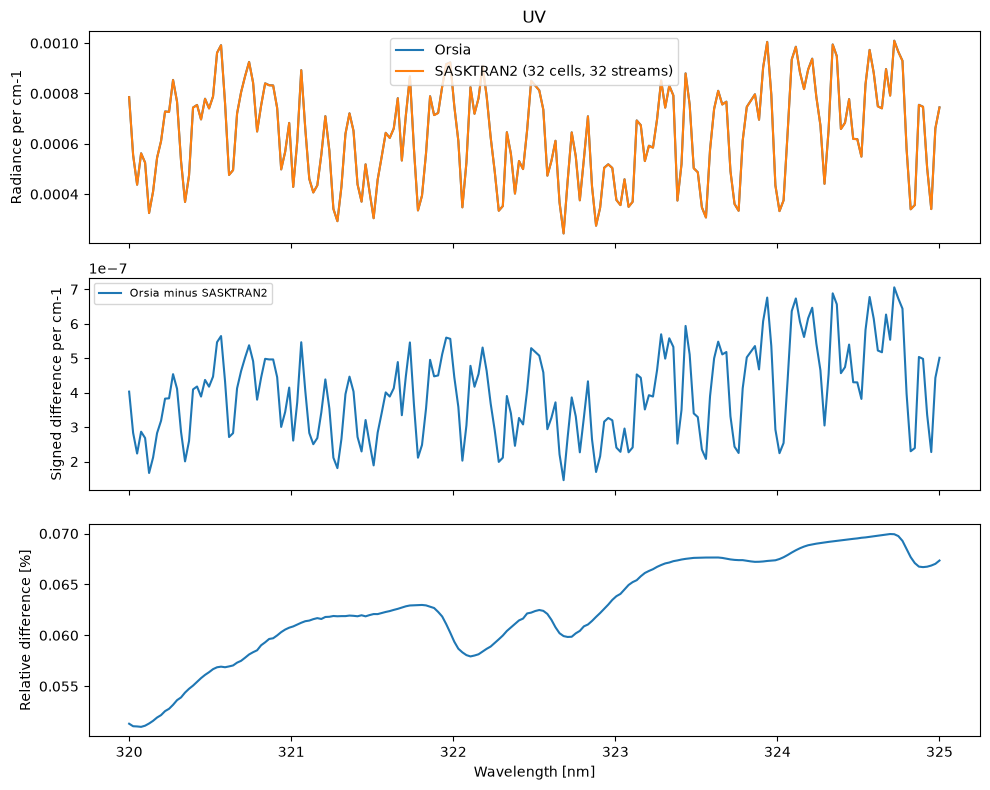

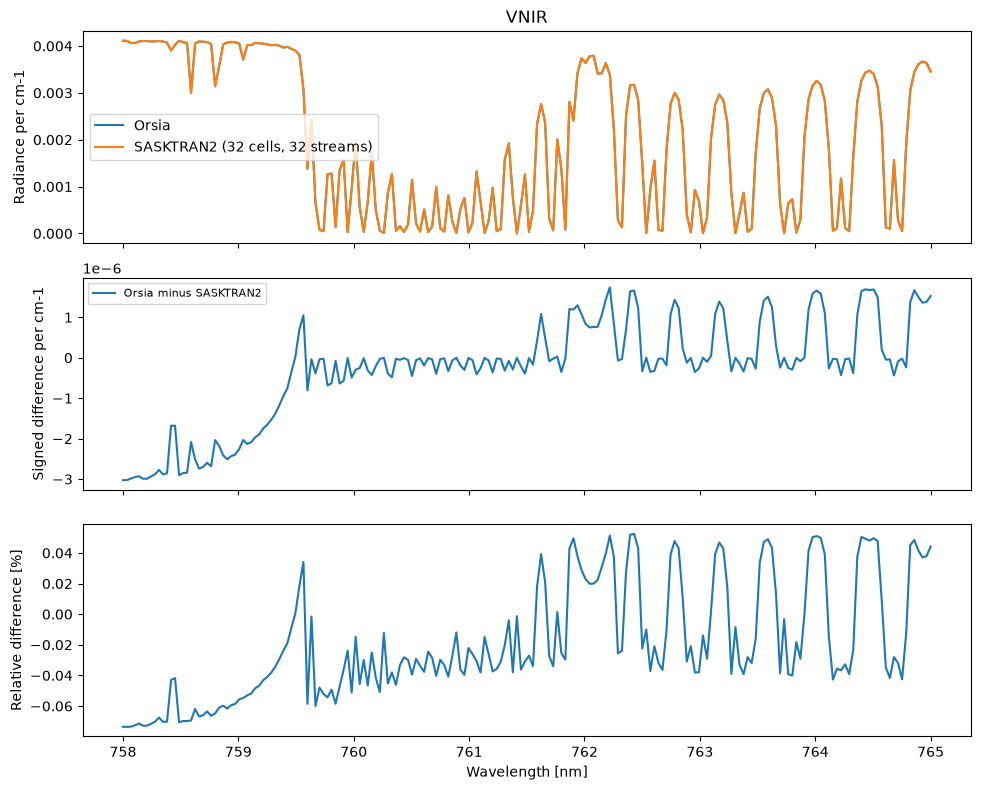

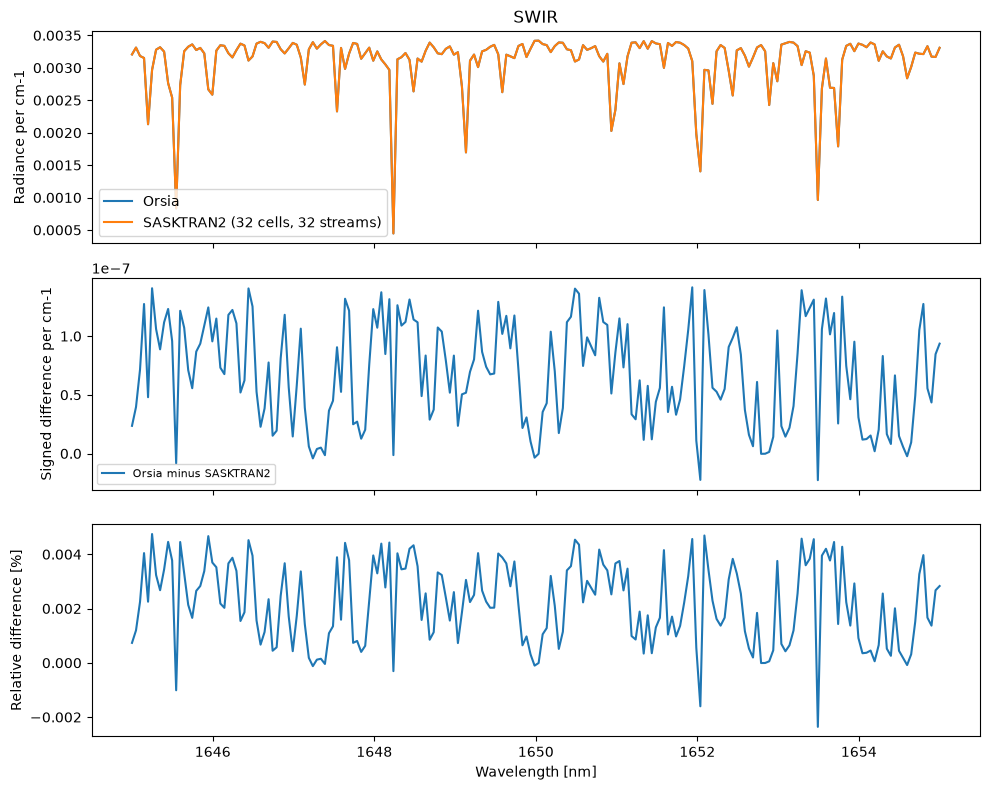

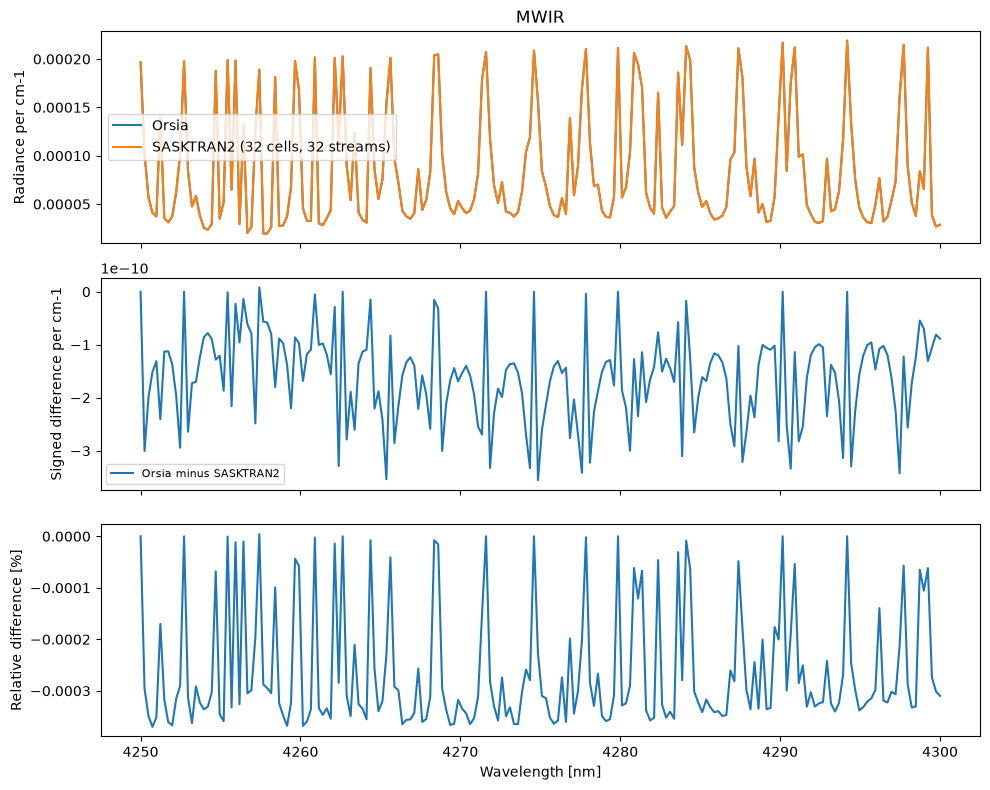

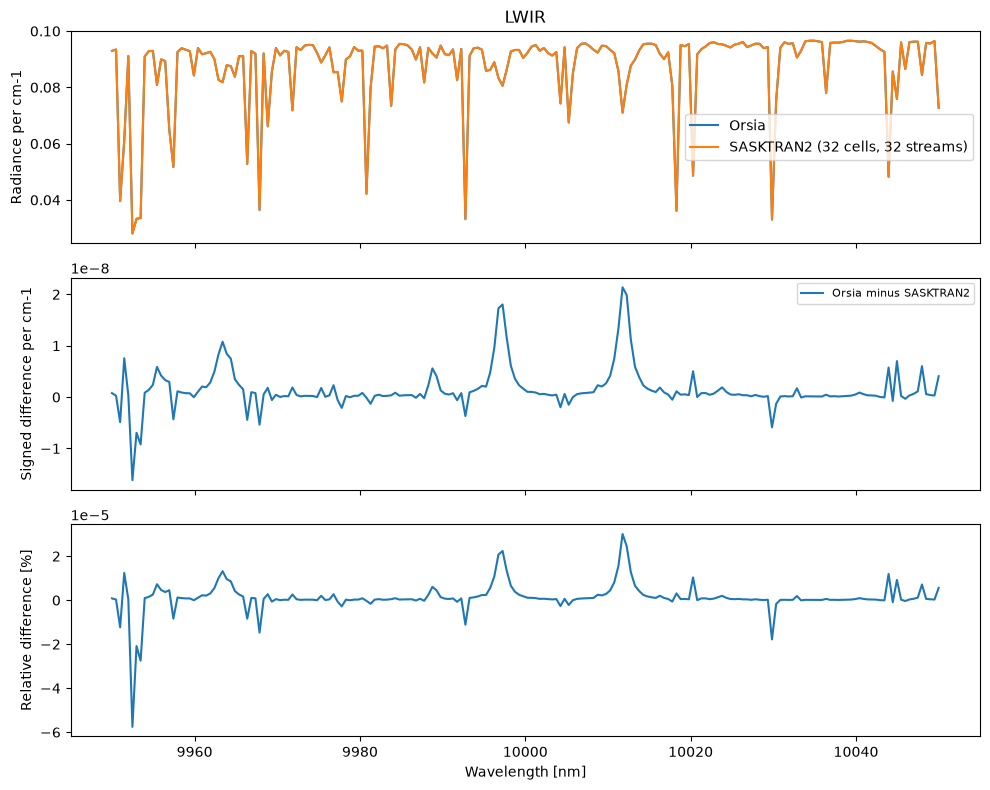

In [5]:
results = {}
for name in CASES:
    grid, scene, optics, source, shared = prepare_case(name)
    if bool(shared['thermal']):
        a, orsia_timing = time_orsia(lambda: thermal.schwarzschild_radiance(scene, optics=optics, hemispheric_method='expn').values)
        orsia_timing['scope'] = 'thermal.schwarzschild_radiance; includes returned Radiance and values'
    else:
        controls = SOLAR_CONTROLS[name]
        a, orsia_timing = time_orsia(lambda: solar.reflected_radiance(scene, source=source, optics=optics, **controls).values)
        orsia_timing['scope'] = 'solar.reflected_radiance; complete call including validation, geometry, scratch allocation, transport and returned Radiance values'
    references = [reference(shared, 32, 32)]
    b = np.asarray(references[-1]['radiance'])
    assert np.all(np.isfinite(a)) and np.all(np.isfinite(b))
    show_comparison(name, grid, a, b)
    results[name] = dict(orsia_timing=orsia_timing, orsia=a.tolist(), reference=references, wavenumbers_cm1=grid.points.tolist())


In [6]:
show_agreement(results)


### Agreement summary
Absolute differences: W m⁻² sr⁻¹ (cm⁻¹)⁻¹. Relative differences: 100 × |Orsia − SASKTRAN2| / |SASKTRAN2|.

| Band | Max absolute difference | Max relative difference [%] |
| --- | ---: | ---: |
| UV | 7.05768e-07 | 0.0699517 |
| VNIR | 3.02513e-06 | 0.0735922 |
| SWIR | 1.41584e-07 | 0.00474571 |
| MWIR | 3.55408e-10 | 0.000370006 |
| LWIR | 2.13598e-08 | 5.75752e-05 |

## Calculation times

Orsia timings are measured in this execution. Each median and min–max range uses three warm calls after a separately recorded first call. Solar timings cover the complete `solar.reflected_radiance(...).values` call, including validation, geometry, allocation and transport; thermal timings cover `thermal.schwarzschild_radiance(..., hemispheric_method='expn').values`.

SASKTRAN2 timings cover `calculate_radiance` on a prepared atmosphere and reused engine. Input preparation, engine construction, thermal boundary adaptation and plotting occur outside these timings. With `REFERENCE_CACHE_MODE='reuse'`, matching references retain their original solve timings: **historical** labels identify these cached measurements, dated below. **Current access** measures this run's reference retrieval, including backend identity verification; it measures a different scope from solve time. Set the mode to `'refresh'` for fresh reference calculations.

Each timing panel uses a zero-baseline linear axis with its own scale. Ratios compare the selected algorithms and settings on this machine; equal-accuracy performance requires a dedicated study.


| Band | Orsia current median [s] | SASKTRAN2 median [s] | Timing source | Current access [s] |
| --- | ---: | ---: | --- | ---: |
| UV | 0.00765691 | 75.2034 | historical | 0.9876 |
| VNIR | 0.000684819 | 81.5301 | historical | 0.9908 |
| SWIR | 0.000507145 | 73.964 | historical | 1.03 |
| MWIR | 9.56e-05 | 0.00368929 | historical | 1.012 |
| LWIR | 0.00015429 | 0.00398811 | historical | 0.9166 |

SASKTRAN2 original computation dates (UTC): UV: 2026-10-17T19:09:14.975175+00:00; VNIR: 2026-10-17T12:02:27.388944+00:00; SWIR: 2026-10-17T12:10:12.400524+00:00; MWIR: 2026-10-17T12:10:18.231997+00:00; LWIR: 2026-10-17T19:09:34.347792+00:00.

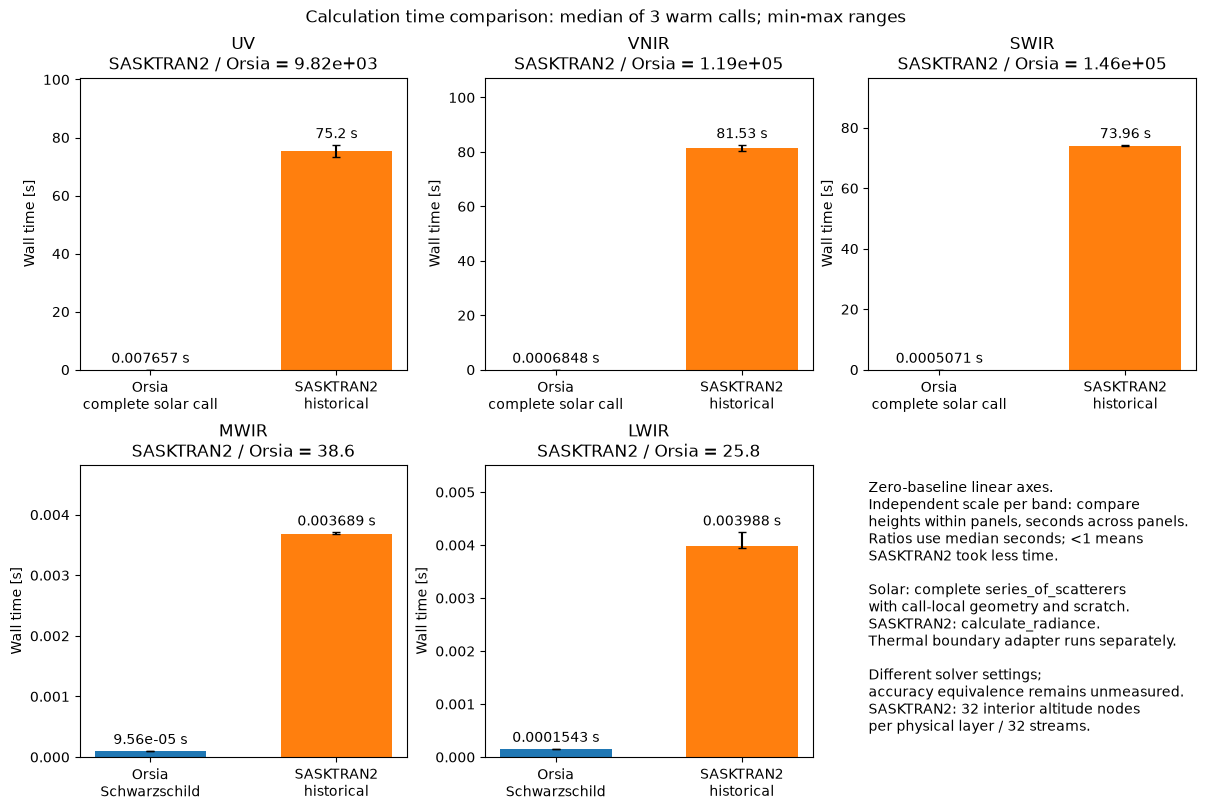

In [7]:
show_timing(results, TIMING_RUNS)
